# RAG - Retrieval Evaluation

This notebook evaluates the **retrieval** half of the RAG pipeline (Chroma + `nomic-embed-text`) against the test set in `../assets/about_me/tests.jsonl`.

For every test question we retrieve the top-K chunks and check whether they contain the expected `keywords`. A chunk is treated as *relevant* for a keyword if it contains that keyword (case-insensitive).

| Metric | What it answers |
|---|---|
| **MRR (keyword)** | Averaged over keywords: `1 / rank` of the first chunk containing that keyword (0 if missing). Rewards putting the evidence near the top. |
| **MRR (any)** | Classic MRR: `1 / rank` of the first chunk containing *any* keyword. |
| **nDCG@k** | Ranking quality. A chunk's gain is the fraction of the question's keywords it contains; earlier chunks count more. |
| **Keyword coverage@k** | Recall: fraction of keywords found anywhere in the top-k. |
| **Hit rate@k (any / all)** | Fraction of questions where at least one / every keyword was found in the top-k. |
| **Precision@k** | Fraction of the top-k chunks containing at least one keyword. |

## Imports and configuration

In [1]:
import json
import math
from pathlib import Path

import pandas as pd

TESTS_PATH = "../assets/about_me/tests.jsonl"
DB_NAME = "../assets/about_me/vector_db"
COLLECTION_NAME = "langchain"

K_VALUES = [1, 3, 5, 10]
MAX_K = max(K_VALUES)
OVERFETCH = 3          # fetch MAX_K * OVERFETCH raw hits so we still have MAX_K after de-duplication
HEADLINE_K = 5         # the k used for the per-category / worst-question views

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

## Load the test data

In [2]:
def load_tests(path: str) -> list[dict]:
    tests = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line:
            tests.append(json.loads(line))
    return tests


tests = load_tests(TESTS_PATH)
df_tests = pd.DataFrame(tests)

print(f"Loaded {len(tests)} test questions")
df_tests["category"].value_counts().to_frame("questions")

Loaded 55 test questions


,questions
category,
direct_fact,13
technical_skills,9
work_experience,7
numerical,6
ai_tools,5
education,4
spanning,4
temporal,2
personal,2


## Metric functions

Each metric lives in its own cell below as a small pure function of `(keywords, docs, k)`, so it can be read, tested and tweaked independently. The first cell holds the shared helpers and a tiny worked example that every metric cell is demonstrated on.

In [3]:
def keyword_ranks(keywords: list[str], docs: list[str]) -> dict[str, int | None]:
    """1-based rank of the first doc containing each keyword (None if no doc does)."""
    texts = [d.lower() for d in docs]
    return {
        kw: next((i for i, t in enumerate(texts, start=1) if kw.lower() in t), None)
        for kw in keywords
    }


def hit_matrix(keywords: list[str], docs: list[str], k: int) -> list[list[bool]]:
    """hits[i][j] -> does the i-th retrieved doc (top-k only) contain keyword j."""
    top = [d.lower() for d in docs[:k]]
    return [[kw.lower() in t for kw in keywords] for t in top]


def keywords_found(keywords: list[str], docs: list[str], k: int) -> list[bool]:
    """found[j] -> does keyword j appear in at least one of the top-k docs."""
    hits = hit_matrix(keywords, docs, k)
    return [any(row[j] for row in hits) for j in range(len(keywords))]


# Worked example used to demonstrate each metric.
# Kafka first appears in chunk 2, Greenplum in chunk 3, Python never appears.
example_docs = [
    "I use Java and Spring Boot.",
    "I built a Kafka event pipeline.",
    "Consumers sink data into a Greenplum warehouse.",
]
example_keywords = ["Kafka", "Greenplum", "Python"]
print(keyword_ranks(example_keywords, example_docs))

{'Kafka': 2, 'Greenplum': 3, 'Python': None}


### 1. MRR (keyword)

Averaged over keywords: each keyword contributes `1 / rank` of the first chunk containing it (0 if it is missing from the top-k). Strict: every keyword has to show up high to score well.

Example: (1/2 + 1/3 + 0) / 3 = **0.2778**

In [4]:
def keyword_mrr(keywords: list[str], docs: list[str], k: int) -> float:
    ranks = keyword_ranks(keywords, docs[:k])
    return sum(1 / r for r in ranks.values() if r) / len(keywords)


print(round(keyword_mrr(example_keywords, example_docs, k=3), 4))

0.2778


### 2. MRR (any)

Classic Mean Reciprocal Rank: `1 / rank` of the first chunk containing *any* keyword, 0 if none does. It only asks how high the first useful chunk is.

Example: first chunk with any keyword is chunk 2, so **0.5**

In [5]:
def mrr_any(keywords: list[str], docs: list[str], k: int) -> float:
    hits = hit_matrix(keywords, docs, k)
    first = next((i for i, row in enumerate(hits, start=1) if any(row)), None)
    return 1 / first if first else 0.0


print(round(mrr_any(example_keywords, example_docs, k=3), 4))

0.5


### 3. nDCG@k

Ranking quality. A chunk's gain is the fraction of the question's keywords it contains, and gains are discounted by `log2(rank + 1)` so earlier chunks matter more. The score is DCG divided by the ideal DCG (the same chunks sorted best-first), so 1.0 means the retrieved chunks are already in the best order.

Example: gains `[0, 1/3, 1/3]` give DCG 0.377 against an ideal of 0.544, so **0.6934**

In [6]:
def ndcg(keywords: list[str], docs: list[str], k: int) -> float:
    n = len(keywords)
    gains = [sum(row) / n for row in hit_matrix(keywords, docs, k)]
    dcg = sum(g / math.log2(i + 1) for i, g in enumerate(gains, start=1))
    idcg = sum(g / math.log2(i + 1) for i, g in enumerate(sorted(gains, reverse=True), start=1))
    return dcg / idcg if idcg > 0 else 0.0


print(round(ndcg(example_keywords, example_docs, k=3), 4))

0.6934


### 4. Keyword coverage@k (recall)

Fraction of the keywords that appear anywhere in the top-k chunks. Ignores order; it answers "did retrieval bring back the evidence at all?"

Example: Kafka and Greenplum found, Python missing, so **2/3 = 0.6667**

In [7]:
def coverage(keywords: list[str], docs: list[str], k: int) -> float:
    found = keywords_found(keywords, docs, k)
    return sum(found) / len(keywords)


print(round(coverage(example_keywords, example_docs, k=3), 4))

0.6667


### 5. Hit rate@k (any / all)

Per question this is 1 or 0. Averaged over the test set it becomes the fraction of questions that were answered by retrieval:

- **any**: at least one keyword was found in the top-k
- **all**: every keyword was found in the top-k (the strict version)

Example: **any = 1, all = 0** (Python is missing)

In [8]:
def hit_any(keywords: list[str], docs: list[str], k: int) -> float:
    return float(any(keywords_found(keywords, docs, k)))


def hit_all(keywords: list[str], docs: list[str], k: int) -> float:
    return float(all(keywords_found(keywords, docs, k)))


print(hit_any(example_keywords, example_docs, k=3), hit_all(example_keywords, example_docs, k=3))

1.0 0.0


### 6. Precision@k

Fraction of the top-k chunks that contain at least one keyword. The denominator is always `k`, even if fewer chunks came back. It penalises noisy results (and duplicate chunks).

Example: chunks 2 and 3 are relevant, chunk 1 is not, so **2/3 = 0.6667**

In [9]:
def precision(keywords: list[str], docs: list[str], k: int) -> float:
    hits = hit_matrix(keywords, docs, k)
    return sum(any(row) for row in hits) / k


print(round(precision(example_keywords, example_docs, k=3), 4))

0.6667


### Combine all metrics for one question

`score` simply calls every metric above and returns them as one dict, which is what the evaluation loop uses.

In [10]:
def score(keywords: list[str], docs: list[str], k: int) -> dict:
    """All retrieval metrics for ONE question using only the top-k docs."""
    return {
        "keyword_mrr": keyword_mrr(keywords, docs, k),
        "mrr_any": mrr_any(keywords, docs, k),
        "ndcg": ndcg(keywords, docs, k),
        "coverage": coverage(keywords, docs, k),
        "precision": precision(keywords, docs, k),
        "hit_any": hit_any(keywords, docs, k),
        "hit_all": hit_all(keywords, docs, k),
    }


print({m: round(v, 4) for m, v in score(example_keywords, example_docs, k=3).items()})

{'keyword_mrr': 0.2778, 'mrr_any': 0.5, 'ndcg': 0.6934, 'coverage': 0.6667, 'precision': 0.6667, 'hit_any': 1.0, 'hit_all': 0.0}


### Sanity check against the hand-worked values

In [11]:
res = score(example_keywords, example_docs, k=3)

assert math.isclose(res["keyword_mrr"], (1 / 2 + 1 / 3) / 3)
assert math.isclose(res["mrr_any"], 0.5)
assert math.isclose(res["ndcg"], 0.6934, abs_tol=1e-4)
assert math.isclose(res["coverage"], 2 / 3)
assert math.isclose(res["precision"], 2 / 3)
assert res["hit_any"] == 1.0 and res["hit_all"] == 0.0

# At k=1 only chunk 1 is visible -> nothing is found
assert score(example_keywords, example_docs, k=1)["coverage"] == 0.0
print("Metric sanity checks passed")

Metric sanity checks passed


## Connect to the vector store

Same setup as `rag_extraction.ipynb`. Make sure Ollama is running with `nomic-embed-text` pulled.

In [12]:
from langchain_ollama import OllamaEmbeddings
from langchain_chroma import Chroma

embeddings = OllamaEmbeddings(base_url="http://localhost:11434", model="nomic-embed-text")

vectorstore = Chroma(
    persist_directory=DB_NAME,
    embedding_function=embeddings,
    collection_name=COLLECTION_NAME,
)

print(f"Chunks in collection: {vectorstore._collection.count()}")

Chunks in collection: 54


## Retrieval with optional de-duplication

The collection can contain the same chunk more than once if the ingestion notebook was run several times. Duplicates take up top-k slots and hurt every metric, so `retrieve` can drop exact duplicates (keeping the best-ranked copy) before cutting to `MAX_K`. We evaluate both ways further down.

In [13]:
def retrieve(question: str, dedupe: bool = True) -> list[str]:
    fetch = MAX_K * OVERFETCH if dedupe else MAX_K
    docs = vectorstore.similarity_search(question, k=fetch)
    texts = [d.page_content for d in docs]

    if dedupe:
        seen, unique = set(), []
        for t in texts:
            key = t.strip()
            if key not in seen:
                seen.add(key)
                unique.append(t)
        texts = unique

    return texts[:MAX_K]

## Run the evaluation

In [14]:
def run_eval(dedupe: bool = True) -> tuple[pd.DataFrame, dict[str, list[str]]]:
    """Returns (long-form results: one row per question x k, retrieved texts per question)."""
    rows, retrieved = [], {}

    for t in tests:
        docs = retrieve(t["question"], dedupe=dedupe)
        retrieved[t["question"]] = docs

        for k in K_VALUES:
            rows.append({
                "question": t["question"],
                "category": t["category"],
                "keywords": t["keywords"],
                "k": k,
                **score(t["keywords"], docs, k),
            })

    return pd.DataFrame(rows), retrieved


results, retrieved = run_eval(dedupe=True)
print(f"Evaluated {results['question'].nunique()} questions at k = {K_VALUES}")

Evaluated 55 questions at k = [1, 3, 5, 10]


## Overall results by k

In [15]:
METRICS = ["keyword_mrr", "mrr_any", "ndcg", "coverage", "precision", "hit_any", "hit_all"]

overall = results.groupby("k")[METRICS].mean().round(3)
overall

,keyword_mrr,mrr_any,ndcg,coverage,precision,hit_any,hit_all
k,,,,,,,
1,0.721,0.764,0.764,0.721,0.764,0.764,0.691
3,0.814,0.852,0.863,0.921,0.491,0.945,0.891
5,0.823,0.859,0.863,0.962,0.371,0.982,0.927
10,0.825,0.859,0.851,0.982,0.245,0.982,0.982


## Results by category (at `HEADLINE_K`)

In [16]:
by_category = (
    results[results["k"] == HEADLINE_K]
    .groupby("category")[METRICS]
    .mean()
    .round(3)
    .assign(questions=lambda d: results[results["k"] == HEADLINE_K].groupby("category").size())
    .sort_values("keyword_mrr")
)
by_category

,keyword_mrr,mrr_any,ndcg,coverage,precision,hit_any,hit_all,questions
category,,,,,,,,
persona,0.200,0.200,0.387,1.000,0.200,1.000,1.000,1
spanning,0.543,0.875,0.756,0.938,0.550,1.000,0.750,4
temporal,0.625,0.750,0.815,0.750,0.200,1.000,0.500,2
technical_skills,0.815,0.833,0.857,0.963,0.444,1.000,0.889,9
direct_fact,0.823,0.823,0.865,1.000,0.385,1.000,1.000,13
numerical,0.833,0.833,0.823,0.833,0.367,0.833,0.833,6
work_experience,0.833,0.833,0.860,1.000,0.286,1.000,1.000,7
ai_tools,0.950,1.000,0.973,1.000,0.360,1.000,1.000,5
certifications,1.000,1.000,1.000,1.000,0.200,1.000,1.000,1


## Visualise

Matplotlib is building the font cache; this may take a moment.


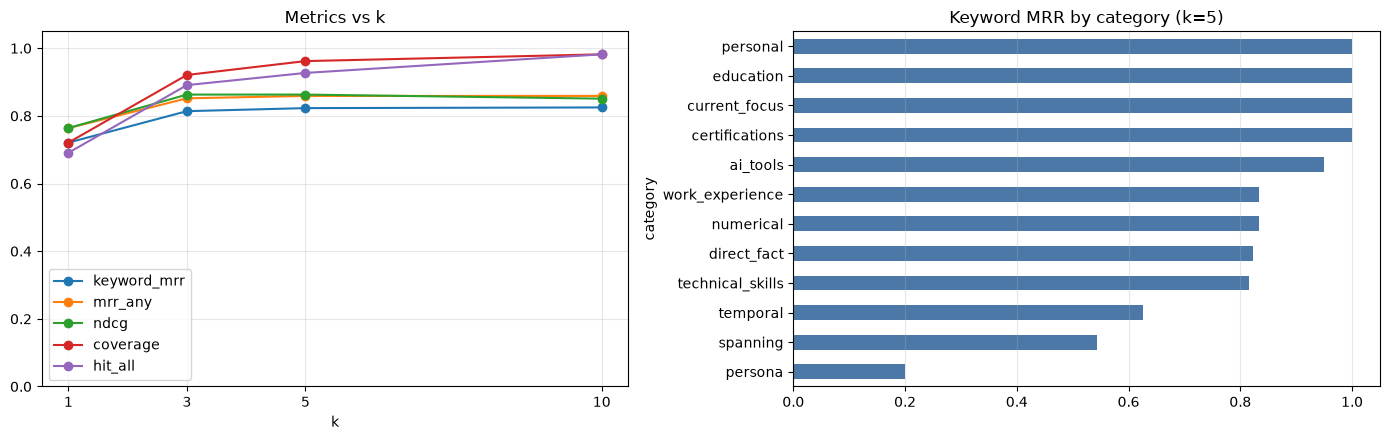

In [19]:
try:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    overall[["keyword_mrr", "mrr_any", "ndcg", "coverage", "hit_all"]].plot(marker="o", ax=axes[0])
    axes[0].set_title("Metrics vs k")
    axes[0].set_xlabel("k")
    axes[0].set_ylim(0, 1.05)
    axes[0].set_xticks(K_VALUES)
    axes[0].grid(alpha=0.3)

    by_category["keyword_mrr"].plot.barh(ax=axes[1], color="#4C78A8")
    axes[1].set_title(f"Keyword MRR by category (k={HEADLINE_K})")
    axes[1].set_xlim(0, 1.05)
    axes[1].grid(alpha=0.3, axis="x")

    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib not installed (run `uv add matplotlib`) - tables above hold the same numbers.")

## Worst-performing questions

These are the best candidates for debugging: poor chunking, a weak embedding match, or a keyword that does not actually appear in the profile.

In [20]:
worst = (
    results[results["k"] == HEADLINE_K]
    .sort_values(["keyword_mrr", "coverage"])
    [["question", "category", "keywords", "keyword_mrr", "coverage", "hit_all"]]
    .head(10)
    .round(3)
)
worst

,question,category,keywords,keyword_mrr,coverage,hit_all
90,How large is the team you lead at Mosambee?,numerical,[9 to 15],0.000,0.000,0.0
46,What is your current job title?,direct_fact,[Lead Engineer],0.200,1.000,1.0
214,How would you describe yourself?,persona,"[builder, tinkerer]",0.200,1.000,1.0
150,Where did you work before Mosambee?,temporal,"[Loylty Rewardz, Technical Solution Architect]",0.250,0.500,0.0
142,List all the companies you have worked for.,spanning,"[Mosambee, Loylty Rewardz, Boku, Tech Mahindra]",0.312,0.750,0.0
162,What technologies are you strongest in?,technical_skills,"[Java, Spring Boot, Kafka]",0.333,0.667,0.0
138,Did you ever work abroad?,work_experience,[Milton Keynes],0.333,1.000,1.0
14,Where do you live?,direct_fact,[Mumbai],0.500,1.000,1.0
42,How many years of experience do you have?,direct_fact,[16 years],0.500,1.000,1.0
94,Which observability tools do you use?,technical_skills,"[Grafana, Prometheus, ELK]",0.500,1.000,1.0


### Inspect what was retrieved for the weakest question

In [23]:
def show_retrieval(question: str, preview_chars: int = 160) -> None:
    test = next(t for t in tests if t["question"] == question)
    docs = retrieved[question]
    ranks = keyword_ranks(test["keywords"], docs)

    print(f"Q: {question}")
    print(f"Expected keywords: {test['keywords']}")
    print(f"First rank per keyword: {ranks}\n")

    for i, d in enumerate(docs, start=1):
        matched = [kw for kw in test["keywords"] if kw.lower() in d.lower()]
        flat = " ".join(d.split())
        print(f"#{i:<2} matched={matched}\n    {flat[:preview_chars]}...\n")


show_retrieval(worst.iloc[0]["question"])

Q: How large is the team you lead at Mosambee?
Expected keywords: ['9 to 15']
First rank per keyword: {'9 to 15': None}

#1  matched=[]
    ### Mosambee (Synergistic Financial Networks), a Pine Labs company — Lead Engineer (March 2023 to present) At Mosambee in Mumbai (fintech payments and POS), I a...

#2  matched=[]
    ## Frequently Asked Questions **What do you do for a living?** I work as a Lead Engineer and Architect at Mosambee (a Pine Labs company), where I own a payments...

#3  matched=[]
    My name is Hatim Motorwala and I work as a Lead Engineer and Architect specializing in software architecture, APIs, and distributed systems. I have 16 years of ...

#4  matched=[]
    ### Boku Inc — Senior Software Engineer (April 2019 to September 2021) At Boku in Mumbai (mobile carrier billing / payments), I was a Senior Software Engineer. ...

#5  matched=[]
    ### Tech Mahindra (British Telecom account) — Technical Consultant & Associate (August 2010 to September 2016) At Tech Mahin

## Pass / fail gate

Simple thresholds so the notebook can be used as a regression check after changing chunk size, overlap, the embedding model, or `k`.

In [ ]:
THRESHOLDS = {"keyword_mrr": 0.60, "ndcg": 0.70, "coverage": 0.85, "hit_any": 0.95}

row = overall.loc[HEADLINE_K]
for metric, minimum in THRESHOLDS.items():
    status = "PASS" if row[metric] >= minimum else "FAIL"
    print(f"{status}  {metric:<12} {row[metric]:.3f}  (min {minimum})")

## Does de-duplication matter?

Re-run the same evaluation without removing duplicate chunks and compare at `HEADLINE_K`.

In [ ]:
results_raw, _ = run_eval(dedupe=False)

compare = pd.concat(
    {
        "deduped": results[results["k"] == HEADLINE_K][METRICS].mean(),
        "raw (no dedupe)": results_raw[results_raw["k"] == HEADLINE_K][METRICS].mean(),
    },
    axis=1,
).round(3)
compare["delta"] = (compare["deduped"] - compare["raw (no dedupe)"]).round(3)
compare

## Export per-question results (optional)

In [ ]:
results.assign(keywords=results["keywords"].apply(json.dumps)).to_csv("retrieval_eval_results.csv", index=False)
print("Saved retrieval_eval_results.csv")